# 教程 2　谁最擅长看见一条微弱的谱线？

计算 X 射线望远镜的两种 figure of merit，并画出 HUBS 白皮书的 Fig. 3

## 问题是什么

星系周围包着一层极其稀薄、温度约一百万度的热气体，叫环星系介质（circumgalactic
medium，CGM）。 它的辐射主要是几条 X 射线谱线，比如氧离子 O VII 在 0.57
keV 附近的三重线、O VIII 在 0.65 keV 的 Lyα 线。 有两种办法看见它：

-   **发射线**：直接对着这团弥散的气体看，它自己会发出谱线。源是**展开**的，比望远镜的视场还大。
-   **吸收线**：找一个躲在气体后面的明亮点源（比如类星体），看它的连续谱被气体”啃掉”一条吸收线。源是**点状**的。

不论哪种，这些谱线都非常**弱**，藏在比它亮得多的连续谱和背景下面。
这份教程要回答的问题是：

> 同样的观测时间，哪台 X 射线望远镜能把一条弱谱线探测得最显著？

我们会推导两个”品质因数”（figure of
merit，FoM），一步步从各任务的响应文件里把它们算出来，最后画出 HUBS
白皮书的 Fig. 3。

> **开始之前**
>
> 先运行 **教程 1（`01_data.qmd`）**，它会把需要的文件放进 `data/`。
> 本教程只读 `data/`，不联网。全部运行约 20 秒，内存峰值约 150 MB。

In [1]:
import os, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from astropy.io import fits
from numpy.lib.stride_tricks import sliding_window_view

DATA = 'data'
FIG = 'figures'                       # 最后的 Fig. 3 存在这里
os.makedirs(FIG, exist_ok=True)
D = lambda *a: os.path.join(DATA, *a)
HC = 12.398419843                     # hc，单位 keV·Å：E[keV] = HC / λ[Å]
EG = np.geomspace(0.09, 10.2, 1500)   # 画图用的能量网格（keV），对数均匀
T0 = time.time()


def have(*files):
    """这些数据文件都在吗？缺了就跳过这台仪器（例如没有自备的 HUBS 文件）。"""
    miss = [f for f in files if not os.path.exists(f)]
    if miss:
        print('跳过：缺少', ', '.join(miss))
    return not miss

## 物理准备

### 光子计数和泊松噪声

X 射线望远镜**一个一个地数光子**，每个光子都记下能量。
光子什么时候到达是随机的：平均应该数到 $N$ 个时，实际数到的个数有
$\sqrt{N}$ 左右的涨落（泊松统计）。
所以想要把一个信号”看出来”，关键是**信号比噪声大多少**，即信噪比 $S/N$。

### 有效面积 $A(E)$

如果源在能量 $E$ 附近每秒每平方厘米每 keV 送来 $F(E)$
个光子，望远镜每秒每 keV 记录到的光子数就是 $F(E)\,A(E)$。 $A(E)$
叫**有效面积**，单位
cm²。它已经把镜面的反射率、滤光片的透过率、探测器的量子效率都乘进去了。
它随能量变化很大：例如在碳、氧、硅的吸收边附近会突然下降。$A(E)$ 存在
ARF 文件里。

### 能量分辨率 $\Delta E$ 和分辨本领 $R$

即使送来的光子能量都精确等于 $E$，探测器记录下的能量也会散开成一个”峰”。
这个峰的半高全宽（FWHM）叫**能量分辨率** $\Delta E$；$R = E/\Delta E$
叫**分辨本领**。 $R$ 越大，谱线在谱上越窄、越尖。这个峰的形状存在 RMF
文件里。

几类仪器的 $R$ 差别很大：

-   **CCD**（XMM、Chandra、eROSITA、AXIS 的成像探测器）：在 1 keV 处
    $R\approx 15$。
-   **微量能器**（HUBS、XRISM、NewAthena）：测量吸收光子后的温度升高，$\Delta E$
    只有 1–5 eV，1 keV 处 $R\approx 200$–$1700$。
-   **光栅**（RGS、HETG、Arcus）：像三棱镜一样按波长把光色散开，$R$
    可达几百到几千，代价是有效面积小。

### 视场 $\Omega$ 和渐晕

望远镜一次能看到的天区叫**视场**，用立体角 $\Omega$ 表示，单位
arcmin²（1° = 60′）。 X
射线是靠掠射反射聚焦的，偏离光轴越远，收集效率越低，这叫**渐晕**（vignetting）。
记偏轴角为 $\theta$，渐晕因子 $V(E,\theta) = A(E,\theta)/A(E,0)$。

## 推导两种 FoM

### 点源上的一条弱吸收线：$\text{FoM}_\text{ab}$

设背景点源的连续谱是 $F_c$（光子 / cm² / s /
keV），一条吸收线”啃掉”了等效宽度 $W$（单位
keV）那么多的光子。曝光时间为 $t$。

-   **信号**：少掉的光子数 $S = W F_c A t$；
-   **噪声**：在一个分辨单元 $\Delta E$ 里本来就有
    $B = F_c\,\Delta E\,A t$ 个连续谱光子，涨落为 $\sqrt{B}$。

于是

$$
\left(\frac{S}{N}\right)^2 = \frac{(W F_c A t)^2}{F_c\,\Delta E\,A t}
= \frac{W^2 F_c}{E}\;R\,A\;t .
$$

右边第一个因子只和天体有关，和望远镜无关。所以达到同样显著度所需的时间
$t \propto 1/(R A)$。定义

$$
\boxed{\text{FoM}_\text{ab} = R(E)\,A(E)}
$$

它越大，同样的时间里吸收线越显著；或者说达到同样显著度用的时间越短。

### 弥散源的一条弱发射线：$\text{FoM}_\text{em}$

发射线的推导一样：谱线贡献 $S$ 个光子，压在 $B$
个连续谱和背景光子上，$(S/N)^2 \approx S^2/B$。
不同的是源比视场还大：望远镜收集到的光子数不仅正比于面积
$A$，还正比于它**一次看到的天区** $\Omega$。 $S$ 和 $B$ 都正比于
$A\,\Omega\,t$，而 $B$ 还正比于 $\Delta E$，所以

$$
\left(\frac{S}{N}\right)^2 \propto \frac{(A\Omega t)^2}{A\Omega t\,\Delta E} \propto R\,A\,\Omega\;t,
\qquad
\boxed{\text{FoM}_\text{em} = R(E)\,A(E)\,\Omega_\text{FoV}} .
$$

有渐晕时，视场里每一处的面积不同，应该把面积对视场积分（这个量叫
*grasp*）：

$$
A\,\Omega_\text{FoV} \;\to\; \int_\text{FoV} A(E,\theta)\,d\Omega \;=\; A(E,0)\int_\text{FoV} V(E,\theta)\,d\Omega \;\equiv\; A(E,0)\,W(E) .
$$

$W(E)$ 是”按渐晕打了折扣的视场”，单位 arcmin²。第
<a href="#sec-vig" class="quarto-xref">小节 4.4</a>
节会对每台望远镜把它算出来。

### 这些公式成立的前提（务必记住）

1.  **谱线比分辨率窄**（未分辨）。线的光子才会全部落在一个 $\Delta E$
    里。百万度气体的谱线热展宽只有约 0.1 eV，对表里所有仪器都成立。
2.  **连续谱和背景远多于谱线光子**（$B\gg S$），所以
    $N\approx\sqrt{B}$。弱谱线正是这种情况。
3.  **背景和源一样随 $A\Omega$ 增长**，例如天空的弥散 X
    射线背景。各探测器自己的粒子背景各不相同，这里**忽略**了。
4.  **发射线的源均匀、并且大于视场**。点源的发射线就不该乘 $\Omega$。
5.  **只比统计误差**，不考虑标定误差、谱线混叠、观测效率等。
6.  FoM
    只能做**相对比较**。推导里丢掉的常数（例如高斯峰里有多少比例的光子落在
    FWHM 内）对所有仪器都一样。

> **什么时候 FoM 会骗人**
>
> 如果背景低到一个分辨单元里只有零星几个光子（“泊松区”），$B\gg S$
> 不再成立，$R$ 再大也不会让 $S/N$ 无限增长。 这时 FoM
> 会**高估**分辨本领很高的仪器（光栅和微量能器）的优势。

### 多个探测器、多个光栅级次怎么合并

XMM 有三台相机同时观测：MOS1、MOS2、pn。光栅会把同一束光分到 ±1、±2、±3
等不同级次上，每个级次都是一条独立的谱。
各条谱里的光子是**不同的光子**，噪声互相独立。最优地合并独立测量时，信噪比的**平方相加**（就像独立随机变量的方差相加，用”逆方差加权”）：

$$
\left(\frac{S}{N}\right)^2_\text{总} = \sum_i \left(\frac{S}{N}\right)^2_i \;\propto\; \sum_i R_i A_i
\quad\Longrightarrow\quad
\text{FoM} = \sum_i R_i A_i .
$$

一种常见的错误做法是先把几条谱加成一条，再用”平均分辨率”去算。
加成一条谱后，总面积是 $\sum A_i$，线宽是按面积加权的平均
$\sum A_i\Delta E_i / \sum A_i$，于是

$$
\text{FoM}_\text{合并成一条} = \frac{\left(\sum_i A_i\right)^2}{\sum_i A_i/R_i} \;\le\; \sum_i R_i A_i .
$$

不等号来自柯西–施瓦茨不等式。只有所有 $R_i$ 相等时才取等号。
直观地说，把一条很窄的谱和一条很宽的谱加在一起，宽谱的噪声会”污染”窄谱的优势。第
<a href="#sec-hetg" class="quarto-xref">小节 5.10</a>
节会用数字验证这一点。

## 从文件里读出 $A(E)$ 和 $R(E)$

### 读 ARF

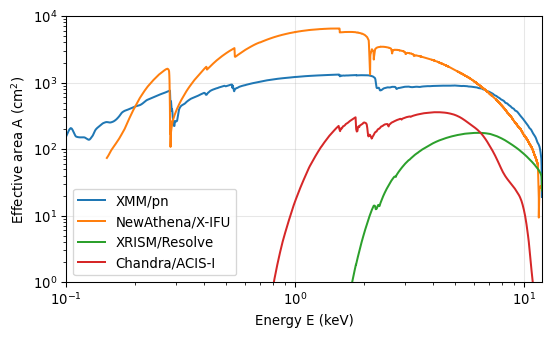

In [2]:
def read_arf(path):
    """返回按能量排好序的 (E [keV], A [cm²])。"""
    d = fits.getdata(path, 'SPECRESP')
    if 'ENERG_LO' in d.names:
        E = (d['ENERG_LO'] + d['ENERG_HI']) / 2
    else:                                   # Arcus 的 ARF 用波长（Å）分格
        E = HC / ((d['BIN_LO'] + d['BIN_HI']) / 2)
    o = np.argsort(E)
    return E[o], np.asarray(d['SPECRESP'], float)[o]


def on(E, y):
    """插值到画图网格 EG 上，表格范围以外记为 0。"""
    return np.interp(EG, E, y, left=0., right=0.)


fig, ax = plt.subplots(figsize=(6.4, 3.6))
for lab, f in [('XMM/pn', D('xmm', 'pn-thin-5.arf')),
               ('NewAthena/X-IFU', D('xifu', 'new_athena_xifu_mar_v2_no_filter.arf')),
               ('XRISM/Resolve', D('xrism', 'rsl_pntsrc_GVC_2025.arf')),
               ('Chandra/ACIS-I', D('chandra', 'acisi_aimpt_cy28.arf'))]:
    if os.path.exists(f):
        ax.plot(*read_arf(f), label=lab)
ax.set(xscale='log', yscale='log', xlim=(0.1, 12), ylim=(1, 1e4), xlabel='Energy E (keV)', ylabel='Effective area A (cm$^2$)')
ax.legend(); ax.grid(alpha=.3); plt.show()

注意几个特征：

-   0.28 keV（碳）和 0.53
    keV（氧）处的吸收边，来自滤光片和探测器表面的材料。
-   XRISM 在 2 keV 以下几乎没有面积。它的闸门阀（gate
    valve）至今没有打开，阀门上的铍窗吸收了软 X 射线。
-   Chandra/ACIS-I 的软 X
    射线面积，被探测器表面多年积累的污染层吃掉了大半。

### 读 RMF：一个真实能量 → 一个”峰”

RMF 的第 $i$ 行告诉我们：真实能量为 $E_i$
的光子，被记录在各个道（channel）的概率。 道 $c$ 对应的能量范围
`E_MIN[c]–E_MAX[c]` 在 `EBOUNDS` 表里。
有的仪器各个道的宽度不一样，所以我们把概率**除以道宽**，得到”每 keV
的概率密度”，再量它的半高全宽：

1.  找到最高点 $y_\text{max}$；
2.  向左、向右各走到第一个低于 $y_\text{max}/2$ 的点；
3.  在相邻两点之间线性插值，得到左右两个半高点
    $x_l$、$x_r$，$\Delta E = x_r - x_l$。

光栅的 CCD
之间有缝隙，谱线可能正好落在缝上，**一侧被截断**。截断的特征是：相邻两点之间突然掉到十分之一以下。
这时用完好的那一侧半宽乘 2；两侧都被截断，这一行就作废。

In [3]:
def _cliff(y, j, step, n=3):
    """从 j 往 step 方向看 n 步，有没有"断崖"（下一点不到上一点的 1/10，或到了数组尽头）？"""
    for m in range(n):
        a, b = j + m * step, j + (m + 1) * step
        if b < 0 or b >= len(y) or y[b] < 0.1 * y[a]:
            return True
    return False


def fwhm(x, y):
    """峰 y(x) 的半高全宽；x 递增。"""
    k = int(np.argmax(y))
    half = y[k] / 2
    i = k
    while i > 0 and y[i - 1] > half:
        i -= 1
    j = k
    while j < len(y) - 1 and y[j + 1] > half:
        j += 1
    if i == 0 or j == len(y) - 1:
        return np.nan
    xl = x[i - 1] + (half - y[i - 1]) * (x[i] - x[i - 1]) / (y[i] - y[i - 1])
    xr = x[j] + (y[j] - half) * (x[j + 1] - x[j]) / (y[j] - y[j + 1])
    cut_l, cut_r = _cliff(y, i, -1), _cliff(y, j, +1)
    if cut_l and cut_r:
        return np.nan
    if cut_l:
        return 2 * (xr - x[k])
    if cut_r:
        return 2 * (x[k] - xl)
    return xr - xl


def rmf_rows(path):
    """逐行给出 (E_i, 道能量 x, 每 keV 的密度 y, 整行之和)。"""
    with fits.open(path) as h:
        eb, m = h['EBOUNDS'].data, h['MATRIX']
        ec = (eb['E_MIN'] + eb['E_MAX']) / 2.
        w = np.abs(eb['E_MAX'] - eb['E_MIN']).astype(float)
        w[w == 0] = np.nan
        tlmin, d = m.header['TLMIN4'], m.data
        for r in range(len(d)):
            ch = (d['F_CHAN'][r][0] - tlmin + np.arange(d['N_CHAN'][r][0])
                  if d['N_GRP'][r] and len(d['F_CHAN'][r]) else np.zeros(0, int))
            x, y = ec[ch], np.asarray(d['MATRIX'][r], float) / w[ch]
            o = np.argsort(x)                      # 光栅的道可能按能量递减排列
            yield (d['ENERG_LO'][r] + d['ENERG_HI'][r]) / 2, x[o], y[o], d['ROWSUM'][r]

看看 0.65 keV（O VIII
谱线的能量）的单色光子在四类仪器里被展宽成什么样。右图是左图中间部分的放大：

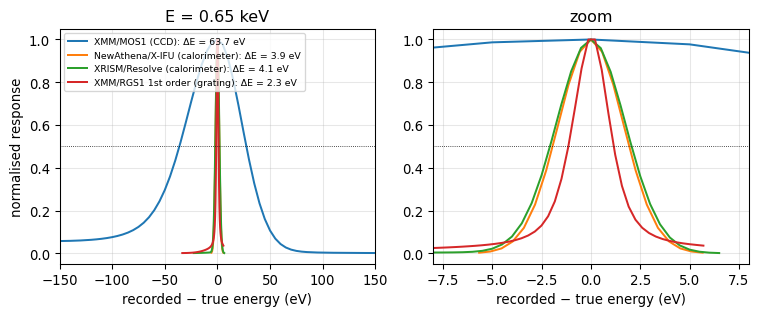

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8, 3.4))
for lab, f in [('XMM/MOS1 (CCD)', D('xmm', 'mos1-thin-5.rmf')),
               ('NewAthena/X-IFU (calorimeter)', D('xifu', 'new_athena_xifu_mar_v2_4eV_gaussian.rmf')),
               ('XRISM/Resolve (calorimeter)', D('xrism', 'rsl_Hp_L_2025.rmf')),
               ('XMM/RGS1 1st order (grating)', D('xmm', 'R1o1.rmf'))]:
    E, x, y, _ = min(rmf_rows(f), key=lambda r: abs(r[0] - 0.65))
    dE = fwhm(x, y)
    for ax in (a1, a2):
        ax.plot((x - E) * 1e3, y / y.max(), label='%s: ΔE = %.1f eV' % (lab, dE * 1e3))
for ax, lim in ((a1, 150), (a2, 8)):
    ax.axhline(0.5, color='k', lw=.6, ls=':')
    ax.set(xlim=(-lim, lim), xlabel='recorded − true energy (eV)')
    ax.grid(alpha=.3)
a1.set(ylabel='normalised response', title='E = 0.65 keV')
a2.set(title='zoom')
a1.legend(fontsize=7, loc='upper left'); fig.tight_layout(); plt.show()

### 从一行行的 $\Delta E$ 到平滑的 $R(E)$

对每一行算出 $\Delta E$，就得到 $R = E/\Delta E$
随能量的变化。有些行不可信，要先剔除：

-   **光栅**：落在坏 CCD 上、或者面积不到最大值 10% 的行。
-   **CCD 和微量能器**：探测阈值以下、整行之和不到附近最大值 10% 的行。

剩下的行再做一个滑动中值，去掉零星的跳点。中值的窗口：光栅取 9
个点，其他仪器取 3 个点。

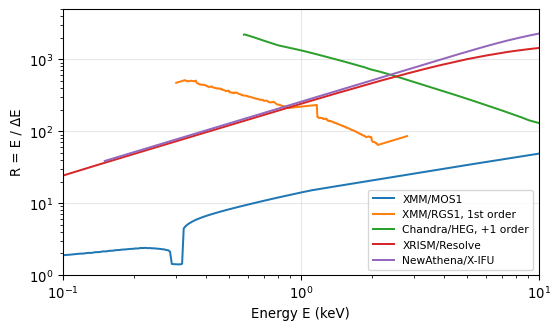

In [5]:
def runmed(y, k):
    p = k // 2
    return np.median(sliding_window_view(np.pad(y, p, mode='edge'), k), axis=1)


def resolution(path, grating=False):
    """(E, R)：每一行的 FWHM → 剔除不可信的行 → 滑动中值。"""
    E, dE, area = map(np.array, zip(*[(e, fwhm(x, y) if len(x) > 2 else np.nan, s)
                                      for e, x, y, s in rmf_rows(path)]))
    good = np.isfinite(dE) & (dE > 0)
    if grating:
        ok, k = good & (area > 0.1 * area.max()), 9
    else:
        n = max(3, len(area) // 20)
        local_max = np.array([area[max(0, i - n // 2):i + n // 2 + 1].max() for i in range(len(area))])
        ok, k = good & (area > 0.1 * local_max) & (area > 1e-3 * area.max()), 3
    return E, E / np.interp(E, E[ok], runmed(dE[ok], k))


fig, ax = plt.subplots(figsize=(6.4, 3.6))
for lab, f, g in [('XMM/MOS1', D('xmm', 'mos1-thin-5.rmf'), False),
                  ('XMM/RGS1, 1st order', D('xmm', 'R1o1.rmf'), True),
                  ('Chandra/HEG, +1 order', D('chandra', 'aciss_heg1_cy28.grmf'), True),
                  ('XRISM/Resolve', D('xrism', 'rsl_Hp_L_2025.rmf'), False),
                  ('NewAthena/X-IFU', D('xifu', 'new_athena_xifu_mar_v2_4eV_gaussian.rmf'), False)]:
    ax.plot(*resolution(f, g), label=lab)
ax.set(xscale='log', yscale='log', xlim=(0.1, 10), ylim=(1, 5000), xlabel='Energy E (keV)', ylabel='R = E / ΔE')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()

CCD 的 $R$ 大致随 $\sqrt{E}$ 增长；微量能器的 $\Delta E$
近似为常数，所以 $R\propto E$；光栅的 $\Delta\lambda$ 近似为常数，而
$E = hc/\lambda$，所以 $R \propto 1/E$，在软 X 射线最强。

In [6]:
def inst(rmf, arf, grating=False, dE=None):
    """一台仪器在 EG 网格上的 (A, R)。dE 给定时直接用 R = E/dE。"""
    E, R = resolution(rmf, grating)
    if dE is not None:
        R = E / dE
    return on(*read_arf(arf)), on(E, R)

### 渐晕和”有效视场” $W(E)$

$W(E) = \int_\text{FoV} V(E,\theta)\,d\Omega$ 怎么算？把视场切成 0.05′ ×
0.05′ 的小方格，每个格子按它到光轴的距离 $\theta$
查渐晕表，再全部加起来。 视场的形状各不相同：

| 望远镜 | 视场形状 |
|------------------------------------|------------------------------------|
| XMM/MOS | 半径 15′ 的圆。MOS1 先后被微流星体打坏两块 CCD（2005 年 CCD6、2012 年 CCD3），外圈 6 块 CCD 只剩 4 块 |
| XMM/pn | 半径 15′ 的圆，和 27.2′ × 26.2′ 的矩形取交集 |
| eROSITA | 半径 30.94′ 的圆（CALDB 的视场图正是这个圆盘），7 台望远镜按各自面积加权平均 |
| Chandra/ACIS-I | 16.9′ × 16.9′ 的正方形（4 块 CCD） |
| NewAthena/X-IFU | 外接圆半径 2.18′ 的正六边形（1504 个像元，12.3 arcmin²） |

In [7]:
def grid(hx, hy, step=0.05):
    x = np.arange(-hx + step / 2, hx, step)
    y = np.arange(-hy + step / 2, hy, step)
    X, Y = np.meshgrid(x, y)
    return X, Y, step ** 2


def integrate(theta, V, r, pix):
    """V[θ, E] 表 → 对所有格子求和 Σ V(E, θ(格子)) × 格子面积，得到每个能量的 W。"""
    return np.array([np.interp(r, theta, V[:, k]).sum() * pix for k in range(V.shape[1])])


def W_xmm(cam):
    f = {'mos1': 'XRT1_XAREAEF_0011.CCF', 'mos2': 'XRT2_XAREAEF_0012.CCF', 'pn': 'XRT3_XAREAEF_0014.CCF'}[cam]
    v = fits.getdata(D('xmm', f), 'VIGNETTING')            # 偏轴角 0–15.6′，每 0.6′ 一个点
    E, V = v['ENERGY'] / 1000., np.asarray(v['VIGNETTING_FACTOR'], float).T
    theta = np.arange(V.shape[0]) * 0.6
    X, Y, pix = grid(15, 15)
    r = np.hypot(X, Y)
    inside = r <= 15
    if cam == 'pn':
        inside &= (abs(X) <= 27.2 / 2) & (abs(Y) <= 26.2 / 2)
    W = integrate(theta, V, r[inside], pix)
    if cam == 'mos1':                                       # 中央 CCD 完好，外圈 6 块只剩 4 块
        c = inside & (abs(X) <= 10.9 / 2) & (abs(Y) <= 10.9 / 2)
        Wc = integrate(theta, V, r[c], pix)
        W = Wc + (W - Wc) * 4 / 6
    return np.interp(EG, E, W)


def W_erosita(radius=30.94):
    X, Y, pix = grid(radius, radius, 0.161)
    r = np.hypot(X, Y)
    r = r[r <= radius]
    num = den = 0.
    for tm in range(1, 8):                                  # 7 台望远镜（TM1–TM7）
        t = fits.getdata(D('erosita', 'erosita_vignetting_tm%d_v4.0.fits' % tm), 'VIGNET')[0]
        E, theta = (t['ENERG_LO'] + t['ENERG_HI']) / 2, t['THETA'] * 60
        V = np.asarray(t['VIGNET'], float).reshape(len(theta), len(E))
        a = fits.getdata(D('erosita', 'tm%d_arf_filter_000101v02.fits' % tm))
        A = np.interp(E, (a['ENERG_LO'] + a['ENERG_HI']) / 2, a['SPECRESP'])
        num, den = num + A * integrate(theta, V, r, pix), den + A
    return np.interp(EG, E, num / den)


def W_acisi(side=16.9):
    t = fits.getdata(D('chandra', 'hrmaD1996-12-20vignetN0003.fits'), 1)[0]
    E, theta = (t['ENERG_LO'] + t['ENERG_HI']) / 2, np.asarray(t['THETA'], float)
    V = np.asarray(t['VIGNET'], float).reshape(len(t['PHI']), len(theta), len(E)).mean(0)  # 对方位角平均
    X, Y, pix = grid(side / 2, side / 2)
    return np.interp(EG, E, integrate(theta, V, np.hypot(X, Y).ravel(), pix))


def W_xifu(Rc=2.18):
    # ESA 的 13 行渐晕表：行 = 偏轴角（′），列 = 能量（keV），数值见文件头
    E = np.array([0.20, 0.50, 1.00, 1.49, 2.00, 4.00, 4.51, 6.40, 7.00, 10.00, 12.00])
    theta = np.array([0.00, 0.50, 1.00, 2.00, 3.00, 5.00, 7.00, 10.00, 15.00, 20.00, 28.00])
    V = np.loadtxt(D('xifu', 'NewAthena_Vignetting_1may26_amcn.txt'))
    X, Y, pix = grid(Rc, Rc, 0.01)
    inside = (abs(Y) <= np.sqrt(3) / 2 * Rc) & (np.sqrt(3) * abs(X) + abs(Y) <= np.sqrt(3) * Rc)  # 正六边形
    return np.interp(EG, E, integrate(theta, V, np.hypot(X, Y)[inside], pix))


Wv = {}
for name, fn, area in [('XMM/MOS2', lambda: W_xmm('mos2'), np.pi * 15**2),
                       ('eROSITA', W_erosita, np.pi * 30.94**2),
                       ('Chandra/ACIS-I', W_acisi, 16.9**2),
                       ('NewAthena/X-IFU', W_xifu, 12.3)]:
    try:
        Wv[name] = fn()
        print('%-16s 几何视场 %7.1f arcmin²   1 keV 处 W = %7.1f   6 keV 处 W = %7.1f'
              % (name, area, np.interp(1, EG, Wv[name]), np.interp(6, EG, Wv[name])))
    except FileNotFoundError as e:
        print('跳过', name, e)

XMM/MOS2         几何视场   706.9 arcmin²   1 keV 处 W =   384.9   6 keV 处 W =   342.6
eROSITA          几何视场  3007.4 arcmin²   1 keV 处 W =  1692.4   6 keV 处 W =   823.7
Chandra/ACIS-I   几何视场   285.6 arcmin²   1 keV 处 W =   261.9   6 keV 处 W =   234.3
NewAthena/X-IFU  几何视场    12.3 arcmin²   1 keV 处 W =    12.1   6 keV 处 W =    11.9

$W$
总是小于几何视场，而且能量越高越小：高能光子的掠射角更小，偏轴时损失更多。

## 逐台仪器计算

下面每一节算一台仪器，结果放进两个字典：`em`（$R\,A\,\Omega$，cm²
arcmin²）和 `ab`（$R\,A$，cm²）。 缺数据的仪器会被跳过。

In [8]:
em, ab = {}, {}


def report(name):
    """打印 1 keV 处的数值，方便核对。"""
    i = np.argmin(abs(EG - 1.0))
    s = '%-20s 1 keV:' % name
    if name in em: s += '  R·A·Ω = %.3g cm² arcmin²' % em[name][i]
    if name in ab: s += '  R·A = %.3g cm²' % ab[name][i]
    print(s)

### HUBS（热重子探寻卫星）

HUBS 是我国计划中的空间 X 射线望远镜，用微量能器专门探测 CGM。

-   **视场**：1° × 1° = 3600 arcmin²。
-   **两种像元**：普通像元 $\Delta E = 2$
    eV；视场中心的一小块”小像元”，设计指标 $\Delta E = 0.6$ eV。
-   **两个 ARF**：`hubs_cc_v20201227.arf`
    是**已经计入渐晕的视场平均面积**，1 keV 处约 500 cm²，所以 (a)
    里直接乘 3600 arcmin²，**不能**再乘渐晕；`hubs_cc_s_v20201227.arf`
    是**轴上面积**，用于点源的 (b)。

In [9]:
if have(D('hubs', 'hubs_cc_v20181130.rmf'), D('hubs', 'hubs_cc_v20201227.arf'), D('hubs', 'hubs_cc_s_v20201227.arf')):
    A_fov, R = inst(D('hubs', 'hubs_cc_v20181130.rmf'), D('hubs', 'hubs_cc_v20201227.arf'))
    A_on = on(*read_arf(D('hubs', 'hubs_cc_s_v20201227.arf')))
    em['HUBS'] = A_fov * R * 3600
    ab['HUBS (normal pixel)'] = A_on * R
    ab['HUBS (small pixel)'] = A_on * EG / 0.6e-3            # R = E / 0.6 eV
    report('HUBS'); report('HUBS (small pixel)')

跳过：缺少 data/hubs/hubs_cc_v20181130.rmf, data/hubs/hubs_cc_v20201227.arf, data/hubs/hubs_cc_s_v20201227.arf

### NewAthena / X-IFU

欧洲空间局（ESA）的下一代大型 X 射线天文台。X-IFU 是它的微量能器。

-   **响应**：2026 年 5 月任务采纳评审的发布版，基线分辨率 4 eV（3 eV
    是设计目标）。
-   **滤光片**：滤光轮开放位。4 层隔热滤光片始终在光路里，作用相当于 XMM
    的 Thin 滤光片。
-   **视场**：1504 个像元组成一个正六边形，只有 12.3 arcmin²，比 HUBS
    小约 300 倍。

In [10]:
if have(D('xifu', 'new_athena_xifu_mar_v2_4eV_gaussian.rmf')):
    A, R = inst(D('xifu', 'new_athena_xifu_mar_v2_4eV_gaussian.rmf'), D('xifu', 'new_athena_xifu_mar_v2_no_filter.arf'))
    em['NewAthena/X-IFU'] = A * R * W_xifu()
    ab['NewAthena/X-IFU'] = A * R
    report('NewAthena/X-IFU')

NewAthena/X-IFU      1 keV:  R·A·Ω = 1.78e+07 cm² arcmin²  R·A = 1.47e+06 cm²

### DIXE（弥散 X 射线探测器）

DIXE
是计划安装在中国空间站上的微量能器，**没有聚焦镜**，只用准直器限制视场。

-   **分辨率**：$\Delta E = 6$ eV。
-   **视场**：准直器的响应随偏轴角变化，积分后的有效视场是 87.5 平方度。
-   **只画在 (a) 里**：它的视场有十几度宽，看点源没有意义。

In [11]:
if have(D('dixe', 'DIXE_rsp_v1.0.1.arf')):
    em['DIXE'] = on(*read_arf(D('dixe', 'DIXE_rsp_v1.0.1.arf'))) * EG / 0.006 * 87.5 * 3600
    report('DIXE')

跳过：缺少 data/dixe/DIXE_rsp_v1.0.1.arf

### AXIS

NASA 的”探针级”（Probe）任务候选者，带 CCD 的高角分辨率望远镜。2026 年 9
月的评选没有入选（入选的是红外任务 PRIMA）。 它的发布包同时给了轴上 ARF
和视场平均 ARF，视场直径 24′。

In [12]:
if have(D('axis', 'axis_ccd_20221101.rmf')):
    A, R = inst(D('axis', 'axis_ccd_20221101.rmf'), D('axis', 'axis_onaxis_20230701.arf'))
    A_fov = on(*read_arf(D('axis', 'axis_fovavg_20230701.arf')))
    em['AXIS'] = A_fov * R * np.pi * 12**2
    ab['AXIS'] = A * R
    report('AXIS')

AXIS                 1 keV:  R·A·Ω = 2.3e+07 cm² arcmin²  R·A = 5.94e+04 cm²

### eROSITA

俄德合作的 SRG 卫星上的巡天望远镜，由 7 台并排的望远镜组成，视场宽达
1°。2022 年起处于安全模式，但它的响应是一个很好的参照。

In [13]:
if have(D('erosita', 'onaxis_tm0_rmf_2023-01-17.fits')):
    A, R = inst(D('erosita', 'onaxis_tm0_rmf_2023-01-17.fits'), D('erosita', 'onaxis_tm0_arf_filter_2023-01-17.fits.gz'))
    em['eROSITA'] = A * R * W_erosita()
    ab['eROSITA'] = A * R
    report('eROSITA')

eROSITA              1 keV:  R·A·Ω = 5.18e+07 cm² arcmin²  R·A = 3.06e+04 cm²

### XMM-Newton / EPIC

ESA 1999 年发射、至今仍在工作的 X 射线天文台。三台 CCD 相机
MOS1、MOS2、pn 分别装在三台望远镜后面。 响应用的是 XMM 为第 26
轮观测申请（AO-26）发布的官方文件：Thin 滤光片、视轴上的点源。 按第
<a href="#sec-combine" class="quarto-xref">小节 3.4</a>
节，三台相机各自的 $R A$（或 $R A W$）**相加**。

In [14]:
if have(*[D('xmm', '%s-thin-5.arf' % c) for c in ('mos1', 'mos2', 'pn')]):
    cams = {c: inst(D('xmm', '%s-thin-5.rmf' % c), D('xmm', '%s-thin-5.arf' % c)) for c in ('mos1', 'mos2', 'pn')}
    em['XMM/EPIC'] = sum(A * R * W_xmm(c) for c, (A, R) in cams.items())
    ab['XMM/EPIC'] = sum(A * R for A, R in cams.values())
    report('XMM/EPIC')

XMM/EPIC             1 keV:  R·A·Ω = 7.7e+06 cm² arcmin²  R·A = 2.2e+04 cm²

### XMM-Newton / RGS

MOS1 和 MOS2 前面各挡着一组反射光栅，把约一半的光色散到两台 RGS
上。每台都有一级和二级光谱，一共 4 条独立的谱。
它们的响应文件（RSP）把面积和展宽乘在了一起。教程 1
已经把每行之和拆成了单独的 ARF（`*_area.arf`）。

In [15]:
if have(D('xmm', 'R1o1.rmf')):
    ab['XMM/RGS'] = sum(np.prod(inst(D('xmm', o + '.rmf'), D('xmm', o + '_area.arf'), grating=True), axis=0)
                        for o in ('R1o1', 'R1o2', 'R2o1', 'R2o2'))
    report('XMM/RGS')

XMM/RGS              1 keV:  R·A = 2.43e+04 cm²

### XRISM / Resolve

日美合作、2023 年发射的微量能器任务，$\Delta E \approx 4.5$ eV。
它的闸门阀一直没能打开，2 keV 以下几乎没有面积；对 CGM 最重要的 O VII、O
VIII 谱线（0.5–0.7 keV），它基本看不到。

-   **(b) 点源**：用点源 ARF。
-   **(a) 弥散源**：用”半径 5′ 均匀面源”的
    ARF。它给出的是”从这块天区来的光子”被收集的面积，已经包含渐晕和望远镜点扩散函数的散射，所以乘上这块天区的立体角
    $\pi\cdot5'^2$ 即可。

In [16]:
if have(D('xrism', 'rsl_Hp_L_2025.rmf')):
    A, R = inst(D('xrism', 'rsl_Hp_L_2025.rmf'), D('xrism', 'rsl_pntsrc_GVC_2025.arf'))
    A_ext = on(*read_arf(D('xrism', 'rsl_extflat5_GVC_2025.arf')))
    em['XRISM/Resolve'] = A_ext * R * np.pi * 5**2
    ab['XRISM/Resolve'] = A * R
    report('XRISM/Resolve')

XRISM/Resolve        1 keV:  R·A·Ω = 7.71e-08 cm² arcmin²  R·A = 8.1e-09 cm²

### Chandra / ACIS-I

NASA 1999 年发射的 X 射线天文台，角分辨率最好（0.5″）。 ACIS-I 是 4 块
CCD 拼成的成像阵列。CCD 前面的污染层越积越厚，1 keV
以下的面积几乎全没了。

In [17]:
if have(D('chandra', 'acisi_aimpt_cy28.rmf')):
    A, R = inst(D('chandra', 'acisi_aimpt_cy28.rmf'), D('chandra', 'acisi_aimpt_cy28.arf'))
    em['Chandra/ACIS-I'] = A * R * W_acisi()
    ab['Chandra/ACIS-I'] = A * R
    report('Chandra/ACIS-I')

Chandra/ACIS-I       1 keV:  R·A·Ω = 4.05e+04 cm² arcmin²  R·A = 155 cm²

### Chandra / HETG：多个级次怎么加

HETG 由两套光栅组成：高能光栅 HEG 和中能光栅 MEG。每套都把光分到
±1、±2、±3 级，一共 12 条独立的谱。 下面同时用正确的 $\sum R_iA_i$
和”先合并成一条”的公式 $(\sum A_i)^2/\sum (A_i/R_i)$
算一遍，验证后者总是更小。

In [18]:
if have(D('chandra', 'aciss_heg1_cy28.grmf')):
    orders = [inst(D('chandra', 'aciss_%s%s_cy28.grmf' % (g, o)), D('chandra', 'aciss_%s%s_cy28.garf' % (g, o)), grating=True)
              for g in ('heg', 'meg') for o in ('1', '-1', '2', '-2', '3', '-3')]
    ab['Chandra/HETG'] = sum(A * R for A, R in orders)
    sumA = sum(A for A, R in orders)
    naive = sumA**2 / np.maximum(sum(np.where(R > 0, A / np.where(R > 0, R, 1), 0) for A, R in orders), 1e-30)
    for e in (1, 2, 6):
        i = np.argmin(abs(EG - e))
        print('E = %g keV：Σ R·A = %.3g，合并成一条 = %.3g，比值 %.3f' % (e, ab['Chandra/HETG'][i], naive[i], naive[i] / ab['Chandra/HETG'][i]))

E = 1 keV：Σ R·A = 2.05e+03，合并成一条 = 1.94e+03，比值 0.943
E = 2 keV：Σ R·A = 5.93e+04，合并成一条 = 5.27e+04，比值 0.889
E = 6 keV：Σ R·A = 9.42e+03，合并成一条 = 8.13e+03，比值 0.863

### Arcus（2021 年方案）

为研究 CGM 设计的光栅任务，先后以 MIDEX（2021）和
Probe（2023）方案参评，都没有入选。 这里用的是 2021 年方案的响应：

-   **高分辨率级次**：落在 “far” 相机上的 −2 到 −11
    级，每一级都是独立的谱。
-   **零级**：零级没有色散，分辨率只是 CCD 的水平，但面积大。

In [19]:
if have(D('arcus', 'far_chan_all_-2.rmf')):
    parts = [inst(D('arcus', 'far_chan_all_-%d.rmf' % n), D('arcus', 'far_chan_all_ccdord_-%d_true_-%d.arf' % (n, n)), grating=True)
             for n in range(2, 12)]
    parts.append(inst(D('arcus', 'chan_all_+0.rmf'), D('arcus', 'chan_all_+0.arf')))
    ab['Arcus (2021 design)'] = sum(A * R for A, R in parts)
    report('Arcus (2021 design)')
print('计算用时 %.1f s' % (time.time() - T0))

跳过：缺少 data/arcus/far_chan_all_-2.rmf
计算用时 10.4 s

## 画出 Fig. 3

每台仪器在两幅图里用同一种颜色；未入选的方案（AXIS、Arcus）用点划线。
画两个版本：包含全部任务的，和去掉 AXIS、Arcus 的。

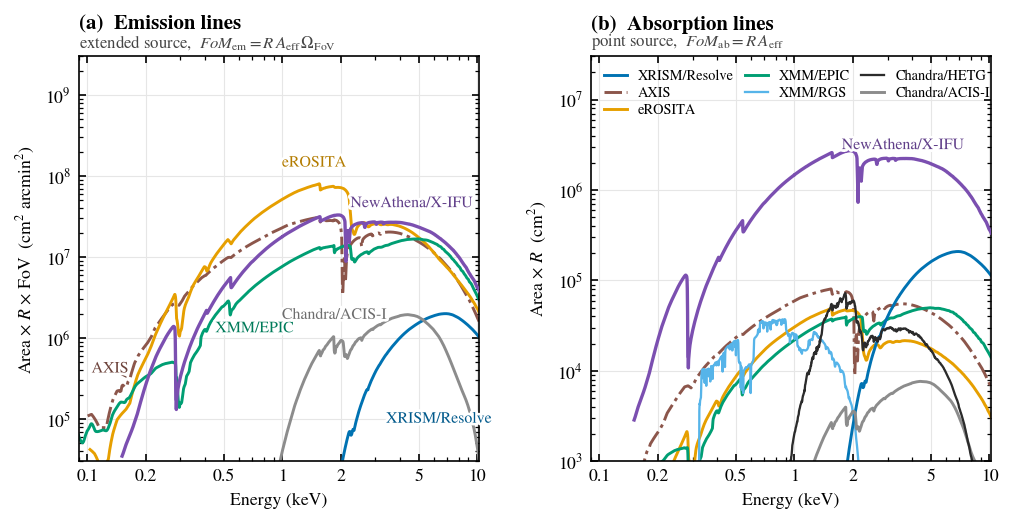

In [20]:
CONCEPT = (0, (6, 1.6, 1.2, 1.6))
STYLE = {
    'HUBS':                dict(color='#D62728', lw=2.6, zorder=10),
    'HUBS (small pixel)':  dict(color='#D62728', lw=2.6, zorder=10),
    'HUBS (normal pixel)': dict(color='#D62728', lw=1.5, ls=(0, (4, 1.6)), zorder=9),
    'NewAthena/X-IFU':     dict(color='#7B4FB0', lw=1.6, zorder=8),
    'DIXE':                dict(color='#CC79A7', lw=1.4),
    'eROSITA':             dict(color='#E69F00', lw=1.4),
    'XMM/EPIC':            dict(color='#009E73', lw=1.4),
    'XMM/RGS':             dict(color='#56B4E9', lw=1.1),
    'XRISM/Resolve':       dict(color='#0072B2', lw=1.4),
    'Chandra/ACIS-I':      dict(color='#8C8C8C', lw=1.4),
    'Chandra/HETG':        dict(color='#2B2B2B', lw=1.1),
    'AXIS':                dict(color='#8C564B', lw=1.4, ls=CONCEPT),
    'Arcus (2021 design)': dict(color='#A07D00', lw=1.4, ls=CONCEPT),
}
SHORT = {'Arcus (2021 design)': 'Arcus', 'HUBS (small pixel)': 'HUBS\nsmall pixels',
         'HUBS (normal pixel)': 'HUBS\nnormal pixels'}
# 曲线旁的标签位置：(能量 keV, log10 y, 水平对齐, 竖直对齐, 引线指向的能量或 None)
LAB = {'em': {'HUBS': (0.40, 8.68, 'right', 'center', None), 'DIXE': (6.3, 8.68, 'center', 'bottom', None),
              'eROSITA': (1.45, 8.08, 'center', 'bottom', None), 'NewAthena/X-IFU': (4.6, 7.58, 'center', 'bottom', None),
              'AXIS': (0.105, 5.62, 'left', 'center', 0.165), 'XMM/EPIC': (0.72, 6.2, 'center', 'top', None),
              'Chandra/ACIS-I': (1.85, 6.2, 'center', 'bottom', None), 'XRISM/Resolve': (3.4, 5.0, 'left', 'center', None)},
       'ab': {'NewAthena/X-IFU': (3.6, 6.42, 'center', 'bottom', None), 'Arcus (2021 design)': (0.56, 6.3, 'center', 'bottom', None),
              'HUBS (small pixel)': (2.36, 5.95, 'left', 'center', None), 'HUBS (normal pixel)': (2.36, 5.5, 'left', 'center', None)}}
LEGEND_B = ('XRISM/Resolve', 'AXIS', 'eROSITA', 'XMM/EPIC', 'XMM/RGS', 'Chandra/HETG', 'Chandra/ACIS-I')
PANELS = (('em', em, (3e4, 3e9), r'Area $\times$ $R$ $\times$ FoV  (cm$^2$ arcmin$^2$)', '(a)  Emission lines',
           r'extended source,  $FoM_{\rm em} = R\,A_{\rm eff}\,\Omega_{\rm FoV}$'),
          ('ab', ab, (1e3, 3e7), r'Area $\times$ $R$  (cm$^2$)', '(b)  Absorption lines',
           r'point source,  $FoM_{\rm ab} = R\,A_{\rm eff}$'))


def darker(c, f=0.78):
    return tuple(f * v for v in matplotlib.colors.to_rgb(c))


def draw(drop=(), name='FoM_fig3'):
    with plt.rc_context({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 8.5,
                         'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
                         'pdf.fonttype': 42}):
        fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.55), dpi=150)
        for ax, (key, d, ylim, ylab, title, sub) in zip(axes, PANELS):
            for k, y in d.items():
                if k in drop:
                    continue
                ax.plot(EG, np.where(y > 0, y, np.nan), **STYLE[k])
                if k in LAB[key]:
                    x0, ly, ha, va, xa = LAB[key][k]
                    kw = dict(ha=ha, va=va, linespacing=1.0, color=darker(STYLE[k]['color']), zorder=20,
                              fontsize=8.2 if 'HUBS' in k else 7.6, fontweight='bold' if 'HUBS' in k else 'normal',
                              path_effects=[pe.withStroke(linewidth=2.6, foreground='white')])
                    if xa is None:
                        ax.text(x0, 10**ly, SHORT.get(k, k), **kw)
                    else:
                        ax.annotate(SHORT.get(k, k), (xa, np.interp(xa, EG, y)), (x0, 10**ly),
                                    arrowprops=dict(arrowstyle='-', color=kw['color'], lw=.6), **kw)
            if key == 'ab':
                ks = [k for k in LEGEND_B if k in d and k not in drop]
                ax.legend([matplotlib.lines.Line2D([], [], **STYLE[k]) for k in ks], ks, loc='upper left', ncol=3,
                          fontsize=6.9, frameon=False, handlelength=1.6, columnspacing=0.75, labelspacing=0.25)
            ax.set(xscale='log', yscale='log', xlim=(0.09, 10.2), ylim=ylim, xlabel='Energy (keV)', ylabel=ylab)
            ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 5, 10], ['0.1', '0.2', '0.5', '1', '2', '5', '10'])
            ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
            ax.grid(color='#E6E6E6', lw=.55)
            ax.set_axisbelow(True)
            ax.set_title(title, loc='left', fontsize=10, fontweight='bold', pad=13)
            ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8, color='#444444', va='bottom')
        fig.tight_layout(w_pad=1.6)
        fig.savefig(os.path.join(FIG, name + '.pdf'))
        fig.savefig(os.path.join(FIG, name + '.png'), dpi=250)
        plt.show()


draw()

去掉未入选的 AXIS 和 Arcus：

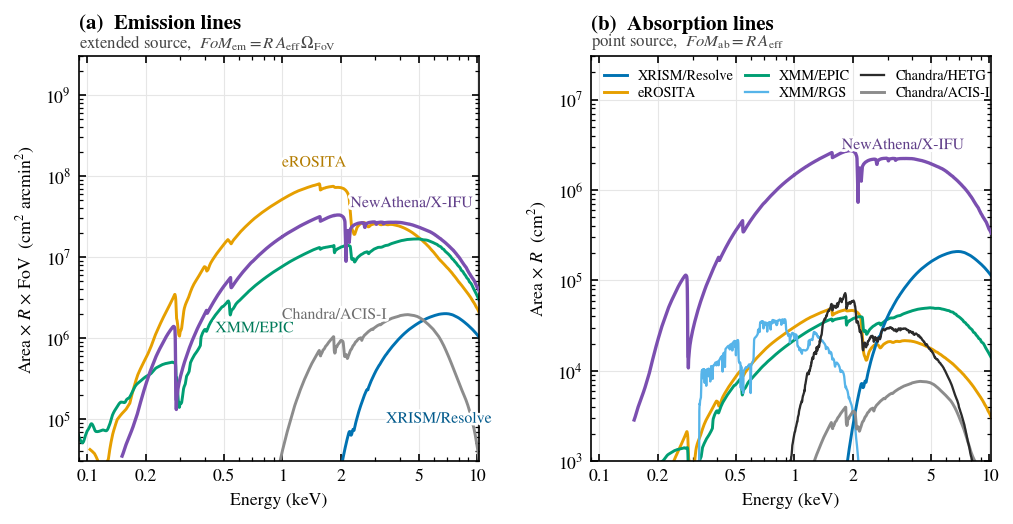

In [21]:
draw(drop=('AXIS', 'Arcus (2021 design)'), name='FoM_fig3_noprobe')

把所有曲线存成表格，方便用别的软件再画：

In [22]:
for key, d, unit in (('em', em, 'cm2 arcmin2'), ('ab', ab, 'cm2')):
    names = list(d)
    np.savetxt(os.path.join(FIG, 'FoM_%s.csv' % key), np.column_stack([EG] + [d[k] for k in names]), fmt='%.5g',
               delimiter=',', header='E_keV,' + ','.join(names) + '   (unit: %s)' % unit, comments='')
print(sorted(os.listdir(FIG)))

['FoM_ab.csv', 'FoM_em.csv', 'FoM_fig3.pdf', 'FoM_fig3.png', 'FoM_fig3_noprobe.pdf', 'FoM_fig3_noprobe.png']

## 读图：几个数字

In [23]:
print('%-22s %12s %12s %12s' % ('', '0.5 keV', '1 keV', '2 keV'))
for key, d, unit in (('em', em, 'R·A·Ω'), ('ab', ab, 'R·A')):
    print('—— %s ——' % unit)
    for k, y in sorted(d.items(), key=lambda kv: -np.interp(1, EG, kv[1])):
        print('%-22s' % k + ''.join('%12.3g' % np.interp(e, EG, y) for e in (0.5, 1, 2)))
if 'HUBS' in em:
    for k in ('NewAthena/X-IFU', 'eROSITA', 'XMM/EPIC'):
        if k in em:
            print('1 keV：HUBS 的 FoM_em 是 %s 的 %.0f 倍' % (k, np.interp(1, EG, em['HUBS']) / np.interp(1, EG, em[k])))
print('全部用时 %.1f s' % (time.time() - T0))

                            0.5 keV        1 keV        2 keV
—— R·A·Ω ——
eROSITA                   1.43e+07    5.18e+07    7.18e+07
AXIS                      9.11e+06     2.3e+07    2.12e+07
NewAthena/X-IFU           4.34e+06    1.78e+07    3.26e+07
XMM/EPIC                  2.49e+06     7.7e+06    1.33e+07
Chandra/ACIS-I                15.4    4.06e+04    9.35e+05
XRISM/Resolve                    0    7.99e-08     2.5e+04
—— R·A ——
NewAthena/X-IFU           3.57e+05    1.47e+06    2.69e+06
AXIS                      2.33e+04    5.94e+04    5.55e+04
eROSITA                   8.66e+03    3.06e+04    4.65e+04
XMM/RGS                   1.81e+04    2.42e+04    3.23e+03
XMM/EPIC                  7.07e+03     2.2e+04    3.79e+04
Chandra/HETG                 0.491    2.06e+03    5.91e+04
Chandra/ACIS-I              0.0588         155    3.58e+03
XRISM/Resolve                    0    8.41e-09    2.59e+03
全部用时 15.1 s

几点观察：

1.  **弥散发射线 (a)：HUBS 遥遥领先。** 它同时拥有微量能器的高 $R$ 和 1
    平方度的大视场。X-IFU 的 $R$ 和面积都不差，但视场小了约 300 倍。
2.  **点源吸收线 (b)：HUBS 小像元和 X-IFU 不相上下。** 在 0.2–0.9
    keV，2021 年方案的 Arcus 光栅最好。现有的 RGS、HETG
    要低一到两个量级。
3.  **在 CGM 最重要的 0.5–0.7 keV，在轨的 XRISM
    帮不上忙**：它的闸门阀没开。
4.  这些都是第 <a href="#sec-fom" class="quarto-xref">小节 3</a>
    节那些假设下的**统计**比较。

## 练习

1.  把 HUBS 小像元的 $\Delta E$ 从 0.6 eV 改成 1 eV，(b)
    里的曲线变成多少？它和 X-IFU 谁高？
2.  第 <a href="#sec-hetg" class="quarto-xref">小节 5.10</a>
    节里，为什么 6 keV 处”合并成一条”的损失比 1 keV 处大？（提示：比较
    HEG 和 MEG、一级和三级的 $R$ 在高能处差多少。）
3.  假如 X-IFU 的视场扩大到 HUBS 的 1 平方度，(a) 里 1 keV 处它会是 HUBS
    的几倍？
4.  推导：如果背景可以忽略、谱线光子数又很少（泊松区），$S/N$ 和 $R$
    是什么关系？FoM 应该怎么改？
5.  找一台这里没有的仪器（比如 Swift/XRT 或 Einstein
    Probe/FXT），下载它的 ARF、RMF，加进这张图。